<a href="https://colab.research.google.com/github/PortfolioProg/machine-learning-zoomcamp/blob/main/Homework_4_Zoomcamp_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [ ]:
df.isnull().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [ ]:
categor = df.select_dtypes(include='object').columns.tolist()
numeric = [c for c in df.select_dtypes(exclude='object').columns if c != 'converted']
df[categor] = df[categor].fillna('NA')
df[numeric] = df[numeric].fillna(0.0)
df.isnull().sum()

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

y_train = df_train.converted
y_val = df_val.converted
y_test = df_test.converted

In [ ]:
candidats = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
for col in candidats:
  roc_auc = roc_auc_score(y_train, df_train[col])
  if roc_auc < 0.5:
    roc_auc = 1 - roc_auc
  print(f'{col:30s} f{roc_auc:.3f}')


lead_score                     f0.788
number_of_courses_viewed       f0.723
interaction_count              f0.765
annual_income                  f0.608


In [ ]:
features = numeric + categor
train_dict = df_train[features].to_dict(orient='records')
val_dict = df_val[features].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

In [ ]:
model = LogisticRegression(
solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [ ]:
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
round(auc, 3)

np.float64(0.732)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    predict_positive = (y_pred >= t)

    tp = ((predict_positive == 1) & (y_val == 1)).sum()
    fp = ((predict_positive == 1) & (y_val == 0)).sum()
    fn = ((predict_positive == 0) & (y_val == 1)).sum()

    # защита от деления на ноль
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    precisions.append(p)
    recalls.append(r)

precisions = np.array(precisions)
recalls = np.array(recalls)

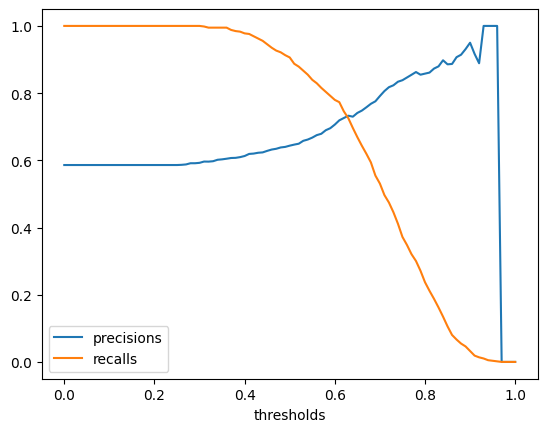

In [ ]:
plt.plot(thresholds, precisions, label='precisions')
plt.plot(thresholds, recalls, label='recalls')
plt.xlabel('thresholds')
plt.legend()
plt.show()

In [ ]:
both_zero = (precisions == 0) & (recalls == 0)
diff = np.abs(precisions - recalls)
diff[both_zero] = np.inf
best_index = diff.argmin()
round(thresholds[best_index], 2)

np.float64(0.63)

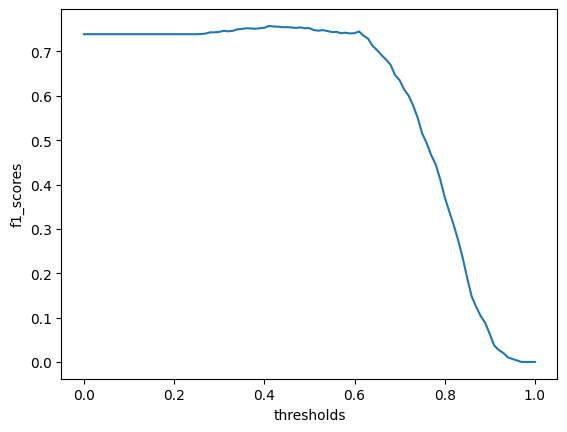

In [ ]:
plt.plot(thresholds, f1_scores)
plt.xlabel('thresholds')
plt.ylabel('f1_scores')
plt.show()

In [ ]:
wdenominator = precisions + recalls
f1_scores = np.divide(2*precisions*recalls, denominator, out=np.zeros_like(denominator), where=denominator>0)
best_index = np.argmax(f1_scores)
round(f1_scores[best_index], 2), round(thresholds[best_index], 2)

(np.float64(0.76), np.float64(0.41))

In [22]:

from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_vl = df_full_train.iloc[val_idx]

    y_tr = df_tr["converted"].values
    y_vl = df_vl["converted"].values

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[features].to_dict(orient="records"))
    X_vl = dv.transform(df_vl[features].to_dict(orient="records"))

    model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    model.fit(X_tr, y_tr)

    y_pred = model.predict_proba(X_vl)[:, 1]
    scores.append(roc_auc_score(y_vl, y_pred))

print(scores)
print(f"mean = {np.mean(scores):.3f}, std = {np.std(scores):.3f}")

[np.float64(0.7305601027122453), np.float64(0.7295726148196622), np.float64(0.7363428071259397), np.float64(0.7412454717957564), np.float64(0.7209138590326581)]
mean = 0.732, std = 0.007


In [23]:

def cross_val_auc(df, C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df):
        df_tr = df.iloc[train_idx]
        df_vl = df.iloc[val_idx]

        y_tr = df_tr["converted"].values
        y_vl = df_vl["converted"].values

        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(df_tr[features].to_dict(orient="records"))
        X_vl = dv.transform(df_vl[features].to_dict(orient="records"))

        model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        model.fit(X_tr, y_tr)

        y_pred = model.predict_proba(X_vl)[:, 1]
        scores.append(roc_auc_score(y_vl, y_pred))

    return np.mean(scores), np.std(scores)


results = []
for C in [0.000001, 0.001, 1]:
    mean, std = cross_val_auc(df_full_train, C)
    mean, std = round(mean, 3), round(std, 3)
    results.append((C, mean, std))
    print(f"C={C:<10} mean={mean}  std={std}")

# Лучший C: максимум среднего AUC; при равенстве минимум std; затем минимум C
best = min(results, key=lambda r: (-r[1], r[2], r[0]))
print("Лучший C:", best[0])

C=1e-06      mean=0.617  std=0.019
C=0.001      mean=0.749  std=0.01
C=1          mean=0.732  std=0.007
Лучший C: 0.001
